# Ensemble Learning Dashboard - Colombo Temperature Forecasting (Sri Lanka)
**Author:** Wickramage D.N - 224215R  |  **Submission:** 23 Nov 2026

> **AI disclosure:** the code was developed with help from Claude (AI assistant). The data, experiments and results below were run by me; the interpretation sections are marked for my own words.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Dimashi2002/ensemble-learning-dashboard-lk/blob/main/Ensemble_Dashboard.ipynb)

## 1. Problem & innovation
Sri Lanka's economy (tourism, agriculture, power demand, events) depends on daily weather. This project forecasts **next-day mean temperature in Colombo** and compares **Bagging, Boosting, Stacking and an RF + ARIMA hybrid**.

**Innovation:** a *hybrid* model where **ARIMA captures trend + yearly season** and **Random Forest learns ARIMA's leftover errors** from recent weather (lags of rain, humidity, wind). Everything is shown in an interactive dashboard that compares all models side by side.

_(Edit: add your own one-line use case, e.g. 'helps hotels in Colombo plan cooling demand'.)_

## 2. Data source
**Real Sri Lankan data:** daily weather for Colombo (6.93 N, 79.86 E), 1 Jan 2010 - 31 Dec 2025, from the free **Open-Meteo Historical Weather API** (open data, CC BY 4.0, https://open-meteo.com). Variables: mean/max/min temperature, rainfall, humidity, max wind.
The raw file is stored in `data/colombo_weather_raw.csv`, so the notebook runs without internet.

In [1]:
import os, subprocess, sys
# --- Colab setup: get the project files from GitHub and install libraries ---
if 'google.colab' in sys.modules and not os.path.exists('ens.py'):
    subprocess.run(['git', 'clone', 'https://github.com/Dimashi2002/ensemble-learning-dashboard-lk.git', '/content/repo'], check=True)
    os.chdir('/content/repo')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'], check=True)
print('working dir:', os.getcwd())

working dir: C:\Users\Asus\Desktop\ML\Submission_Ensemble_Dashboard


In [2]:
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import ens
pd.set_option('display.width', 200)

## 3. Cleaning
Rename columns, parse dates, fill tiny gaps (max 3 days) by interpolation, make sure there is one row per day.

In [3]:
df = ens.load_clean('data/colombo_weather_raw.csv')
print(df.shape, df.index.min().date(), '->', df.index.max().date())
print('missing values:', int(df.isna().sum().sum()))
df.describe().round(2)

(5844, 6) 2010-01-01 -> 2025-12-31
missing values: 0


,temp_mean,temp_max,temp_min,rain_mm,humidity,wind_max
count,5844.00,5844.00,5844.00,5844.00,5844.00,5844.00
mean,26.60,29.54,24.27,7.56,83.59,15.80
std,0.96,1.53,1.20,10.99,6.21,4.56
min,21.40,22.00,18.00,0.00,49.00,4.00
25%,25.90,28.60,23.50,1.10,81.00,12.50
50%,26.60,29.30,24.40,3.80,85.00,15.80
75%,27.20,30.40,25.10,10.00,88.00,18.80
max,30.10,35.80,27.60,231.40,96.00,41.90


## 4. EDA

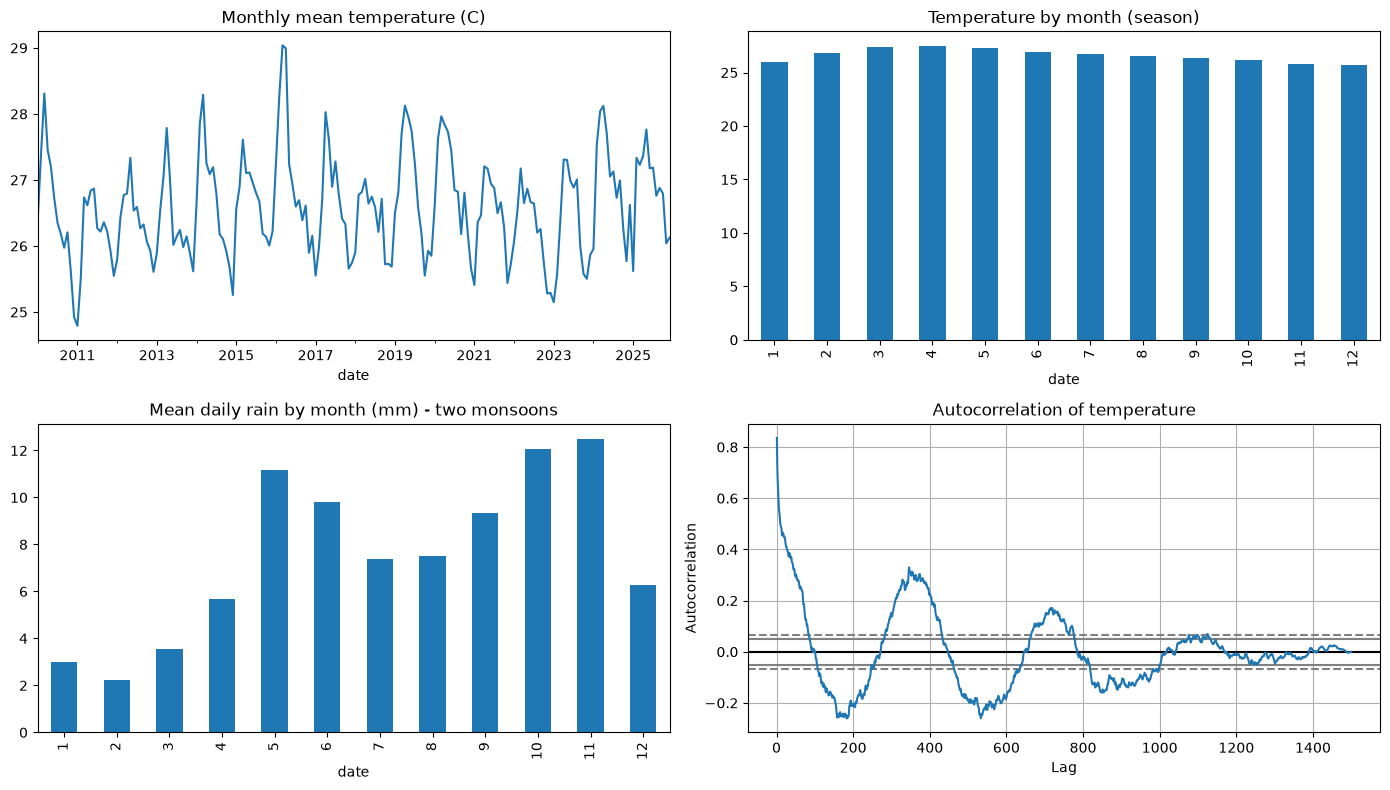

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
df.temp_mean.resample('MS').mean().plot(ax=ax[0,0], title='Monthly mean temperature (C)')
df.groupby(df.index.month).temp_mean.mean().plot.bar(ax=ax[0,1], title='Temperature by month (season)')
df.groupby(df.index.month).rain_mm.mean().plot.bar(ax=ax[1,0], color='tab:blue', title='Mean daily rain by month (mm) - two monsoons')
pd.plotting.autocorrelation_plot(df.temp_mean.iloc[-1500:], ax=ax[1,1]); ax[1,1].set_title('Autocorrelation of temperature')
plt.tight_layout()

**What the plots show (write in your own words):** temperature has a clear yearly cycle (hot Mar-May, cooler Dec-Jan), rainfall peaks in the two monsoon periods, and today's temperature is strongly related to yesterday's (high autocorrelation). That is why lag features and ARIMA make sense.

## 5. Features and split
Features use only **past** information (lags of temperature, rain, humidity, wind; 7- and 30-day rolling means; seasonal sin/cos terms). **Time-based split, no shuffling:** train 2010-2022, test 2023-2025.

In [5]:
feat = ens.make_features(df)
Xtr, Xte, ytr, yte = ens.split(feat)
print('train:', Xtr.index.min().date(), '->', Xtr.index.max().date(), len(Xtr), 'days')
print('test :', Xte.index.min().date(), '->', Xte.index.max().date(), len(Xte), 'days')
print('features:', list(Xtr.columns))

train: 2011-01-01 -> 2022-12-31 4383 days
test : 2023-01-01 -> 2025-12-31 1096 days
features: ['temp_lag1', 'temp_lag2', 'temp_lag3', 'temp_lag7', 'temp_lag14', 'temp_lag365', 'temp_roll7', 'temp_roll30', 'rain_mm_lag1', 'humidity_lag1', 'wind_max_lag1', 'temp_max_lag1', 'temp_min_lag1', 'rain_roll7', 'sin1', 'cos1', 'sin2', 'cos2', 'month']


## 6. Models
| Type | Models |
|---|---|
| Baselines | Persistence (tomorrow = today), Ridge regression |
| **Bagging** | Random Forest (main), Bagging of decision trees, Extra Trees |
| **Boosting** | XGBoost, LightGBM, CatBoost |
| **Stacking** | RF + XGBoost + LightGBM -> Ridge meta-model |
| Time series | SARIMA (ARIMA + yearly Fourier season) |
| **Hybrid** | **RF + ARIMA**: ARIMA forecast + RF forecast of ARIMA's residuals |

All models use the **same split and same metrics** (MAE, RMSE, MAPE, R2).

In [6]:
naive = Xte['temp_lag1'].values
rows = [ens.scores('Persistence (yesterday)', 'Baseline', yte.values, naive, 0.0)]
preds = {'Persistence (yesterday)': naive}
fitted = {}
for n, (g, m) in ens.get_models().items():
    r, p, fm = ens.run_ml(n, g, m, Xtr, Xte, ytr, yte)
    rows.append(r); preds[n] = p; fitted[n] = fm; print('done:', n)

done: Ridge (baseline)


done: Random Forest


done: Bagging (Decision Trees)


done: Extra Trees


done: XGBoost


done: LightGBM


done: CatBoost


done: Stacking (RF+XGB+LGBM -> Ridge)


### Hybrid RF + ARIMA

In [7]:
r_ar, p_ar, r_hy, p_hy, parts = ens.run_hybrid(Xtr, Xte, ytr, yte)
rows += [r_ar, r_hy]; preds[r_ar['Model']] = p_ar; preds['Hybrid RF + ARIMA'] = p_hy
print(parts['arima'].summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sin1           0.6270      0.080      7.809      0.000       0.470       0.784
cos1          -0.4424      0.076     -5.818      0.000      -0.591      -0.293
sin2           0.0722      0.046      1.559      0.119      -0.019       0.163
cos2          -0.2896      0.044     -6.557      0.000      -0.376      -0.203
ar.L1          1.6357      0.013    127.335      0.000       1.611       1.661
ar.L2         -0.6358      0.013    -49.495      0.000      -0.661      -0.611
ma.L1         -0.9542      0.005   -174.694      0.000      -0.965      -0.944
sigma2         0.2107      0.004     56.647      0.000       0.203       0.218


## 7. Model comparison (one table)

,Model,Type,MAE,RMSE,R2,MAPE,Train_seconds
0,Ridge (baseline),Baseline,0.424,0.538,0.723,1.590,0.026
1,Stacking (RF+XGB+LGBM -> Ridge),Stacking,0.424,0.538,0.723,1.589,4.617
2,XGBoost,Boosting,0.424,0.536,0.725,1.590,0.784
3,Hybrid RF + ARIMA,Hybrid,0.426,0.536,0.725,1.596,4.378
4,Random Forest,Bagging,0.427,0.540,0.722,1.600,1.099
5,SARIMA (ARIMA + yearly season),Time series,0.429,0.545,0.716,1.609,4.378
6,Extra Trees,Bagging,0.429,0.541,0.720,1.608,0.600
7,LightGBM,Boosting,0.429,0.543,0.718,1.608,0.388
8,CatBoost,Boosting,0.430,0.543,0.718,1.610,1.063
9,Bagging (Decision Trees),Bagging,0.430,0.544,0.717,1.612,6.014


Lowest MAE: Ridge (baseline)


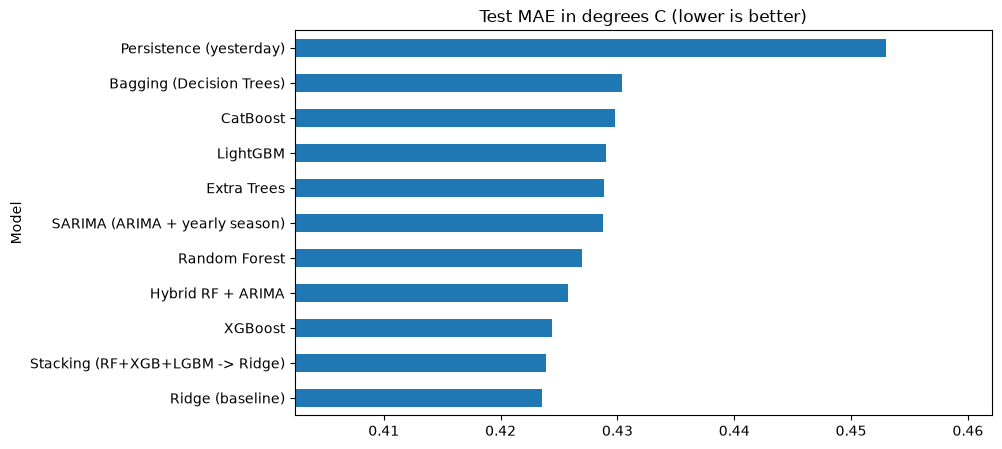

In [8]:
res = pd.DataFrame(rows).sort_values('MAE').reset_index(drop=True)
display(res.round(3))
ax = res.set_index('Model')['MAE'].sort_values().plot.barh(figsize=(9, 5), title='Test MAE in degrees C (lower is better)')
ax.set_xlim(res.MAE.min() * 0.95, res.MAE.max() * 1.02)
print('Lowest MAE:', res.iloc[0].Model)

Text(0, 0.5, 'C')

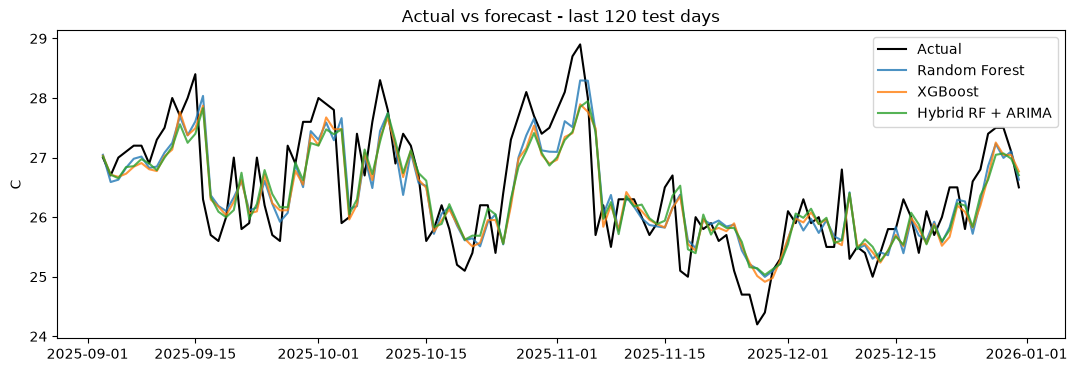

In [9]:
last = 120
plt.figure(figsize=(13, 4)); plt.plot(yte.index[-last:], yte.values[-last:], 'k', label='Actual')
for n in ['Random Forest', 'XGBoost', 'Hybrid RF + ARIMA']:
    plt.plot(yte.index[-last:], preds[n][-last:], label=n, alpha=.8)
plt.legend(); plt.title('Actual vs forecast - last 120 test days'); plt.ylabel('C')

### Interpretation (write in your own words)
Look at the table above and answer: (1) Which model has the lowest error, and by how much? (2) Does boosting beat Random Forest here? (3) Did the hybrid RF + ARIMA beat ARIMA alone and RF alone? (4) Is the gap between the top models large or tiny?

*Points from my run:* the models are extremely close (within about 0.01 C MAE). Next-day temperature is mostly explained by yesterday's temperature and the season, so even the simple Ridge baseline is hard to beat; every ensemble clearly beats the 'tomorrow = today' persistence baseline. Differences this small can be noise, so the practical choice is a simple, fast model. This matches the lecture advice: *choose the simplest model that performs well.*

## 8. Explainability

<Axes: title={'center': 'Random Forest - top features'}>

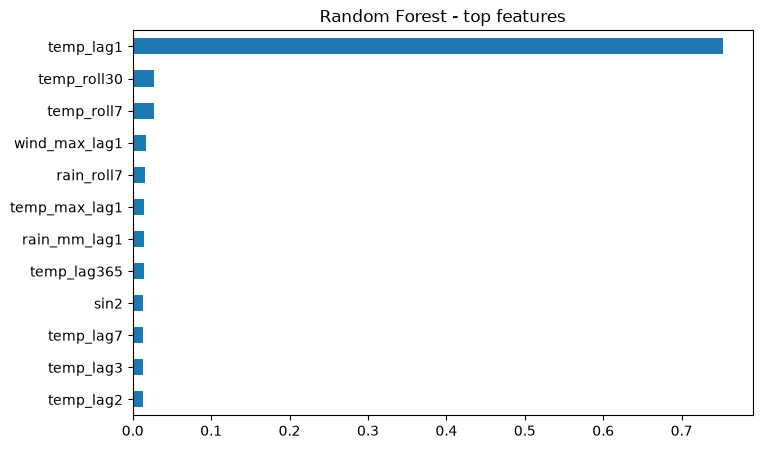

In [10]:
rf = fitted['Random Forest']
imp = pd.Series(rf.feature_importances_, index=Xtr.columns).sort_values().tail(12)
imp.plot.barh(figsize=(8, 5), title='Random Forest - top features')

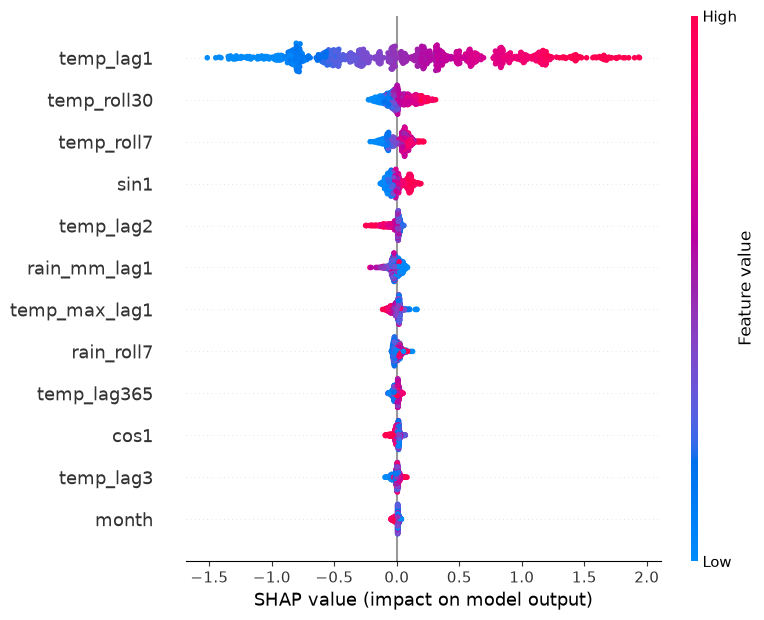

In [11]:
import shap
sv = shap.TreeExplainer(fitted['XGBoost']).shap_values(Xte)
shap.summary_plot(sv, Xte, max_display=12)

**Meaning (own words):** recent temperatures (lag 1, 7-day and 30-day means) and the seasonal terms matter most; rainfall and humidity add a smaller correction (rainy days are cooler), which is exactly what the Random Forest part of the hybrid uses.

## 9. Research discussion
**RF vs gradient boosting (XGBoost, LightGBM, CatBoost).** Random Forest = bagging: many independent trees trained in parallel on bootstrap samples, averaged -> lowers *variance*, robust, little tuning, hard to overfit. Boosting = trees built one after another, each fixing the previous errors -> lowers *bias*, often more accurate, but more sensitive to tuning and noise. XGBoost: regularised, strong all-rounder. LightGBM: fastest, leaf-wise growth, best for big data. CatBoost: native categorical features, good defaults, slower to train. On this data all of them land at nearly the same error, so speed and simplicity decide.

**Tabular vs image/text.** On tabular data tree ensembles are fast, need little preprocessing, handle mixed features and are explainable. On images and text raw pixels/words have no meaningful single-column splits, so CNNs and transformers that learn features win; ensembles would need hand-made features and lose. Ensembles also use more memory and are harder to interpret than a single tree.

**Why a hybrid for time series?** Trees cannot extrapolate trend or repeat a smooth season well; ARIMA can. ARIMA handles that part, the Random Forest handles the non-linear leftover.

## 10. Dashboard
Run locally: `python run_all.py` then `python -m streamlit run app.py` (tabs: dataset, model comparison, actual vs forecast, feature importance, forecast a day).

In [12]:
res.to_csv('results.csv', index=False)
print('saved results.csv')

saved results.csv


## 11. Conclusion & limitations
- Best model by MAE on the 2023-2025 test period: see section 7 (differences between top models are tiny).
- Bagging, boosting, stacking and the RF + ARIMA hybrid were all compared on the same split.
- Limitations: one city, daily data only, reanalysis-based values (not a single weather station), next-day horizon only; longer horizons and extreme events (floods) need more work.
- Future work: rainfall forecasting, more cities (Kandy, Jaffna), Prophet / LSTM comparison.

## 12. References
- Open-Meteo Historical Weather API: https://open-meteo.com (CC BY 4.0)
- scikit-learn, XGBoost, LightGBM, CatBoost, statsmodels documentation
- Lecture notes: Ensemble Learning, Nov 2026